In [1]:
import json
import random
import sys
from difflib import SequenceMatcher
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append('..')
from src.vocabulary import build_vocabulary

In [ ]:
RESULTS = Path('../results')
SEARCH_WIDTH = {'greedy': 256, 'baseline': 1}

In [ ]:
random.seed(0)

In [4]:
rows = []
for path in RESULTS.glob('*/model=*/prompt=*/n-permutations=*/seed=*.json'):
    method, *params = path.relative_to(RESULTS).with_suffix('').parts
    if method not in SEARCH_WIDTH:
        continue
    run = dict(param.split('=', 1) for param in params)
    data = json.loads(path.read_text())
    steps = data['steps']
    *word_set, query = steps[-1]['words']

    rows.append({
        'method': method,
        'model': run['model'].split('--')[-1],
        'task': 'fp' if '_fp_' in run['prompt'] else 'fn',
        'n_permutations': int(run['n-permutations']),
        'seed': int(run['seed']),
        'steps': len(steps) - 1,
        'query': query,
        'set': tuple(word_set),
        'success': steps[-1]['success'],
        'n_success': data['permutations']['n_success'],
    })

runs = pd.DataFrame(rows)
runs['queries'] = runs['steps'] * runs['method'].map(SEARCH_WIDTH) * runs['n_permutations']

## Summary

In [5]:
# steps and queries averaged over successful runs
summary = (
    runs.assign(
        steps=runs['steps'].where(runs['success']),
        queries=runs['queries'].where(runs['success']),
    )
    .groupby(['task', 'model', 'method', 'n_permutations'])
    .agg(
        runs=('seed', 'size'),
        success=('success', 'sum'),
        mean_steps=('steps', 'mean'),
        std_steps=('steps', 'std'),
        mean_queries=('queries', 'mean'),
        std_queries=('queries', 'std'),
        mean_perms=('n_success', 'mean'),
        std_perms=('n_success', 'std'),
    )
)

def highlight_baseline(row):
    style = 'background-color: #5c4b00' if row.name[2] == 'baseline' else ''
    return [style] * len(row)

summary.style.apply(highlight_baseline, axis=1).format(precision=1)

## Greedy vs baseline

In [6]:
# failed run costs infinite queries
p1 = runs.query('n_permutations == 1')

cost = (
    p1.assign(
        cost=p1['queries'].astype(float).where(p1['success'], np.inf)
    )
    .pivot(
        index=['task', 'model', 'seed'],
        columns='method',
        values='cost')
)

pd.DataFrame({
    'greedy_faster': cost['greedy'] < cost['baseline'],
    'baseline_faster': cost['baseline'] < cost['greedy'],
}).groupby(['task', 'model']).sum()

greedy_faster  baseline_faster
task model                                                          
fn   Llama-3.1-8B-Instruct                       16                0
     Mistral-Small-24B-Instruct-2501              1                0
     Qwen2.5-14B-Instruct                        16                4
     Qwen2.5-32B-Instruct                        11                7
     Qwen2.5-7B-Instruct                         17                3
fp   Llama-3.1-8B-Instruct                       20                0
     Mistral-Small-24B-Instruct-2501             19                1
     Qwen2.5-14B-Instruct                        15                0
     Qwen2.5-32B-Instruct                        20                0
     Qwen2.5-7B-Instruct                         16                0

## Permutations

In [ ]:
n_success = (
    runs.query("method == 'greedy'")
    .pivot(
        index=['task', 'model', 'seed'],
        columns='n_permutations',
        values='n_success')
)

pd.DataFrame({
    'mean_p1': n_success[1],
    'mean_p4': n_success[4],
    'p1_better': n_success[1] > n_success[4],
    'p4_better': n_success[4] > n_success[1],
}).groupby(['task', 'model']).agg({
    'mean_p1': 'mean',
    'mean_p4': 'mean',
    'p1_better': 'sum',
    'p4_better': 'sum'
})

mean_p1  mean_p4  p1_better  p4_better
task model                                                                  
fn   Llama-3.1-8B-Instruct               4.75     5.65          7         11
     Mistral-Small-24B-Instruct-2501     0.05     0.05          1          1
     Qwen2.5-14B-Instruct                3.45     5.90          7         13
     Qwen2.5-32B-Instruct                5.30    11.70          1         18
     Qwen2.5-7B-Instruct                 4.95     9.50          2         16
fp   Llama-3.1-8B-Instruct               3.45     9.75          3         15
     Mistral-Small-24B-Instruct-2501     8.55    16.65          4         15
     Qwen2.5-14B-Instruct                2.60     6.85          4         14
     Qwen2.5-32B-Instruct                7.65    11.80          5         12
     Qwen2.5-7B-Instruct                 2.30     6.00          6         11

## False positive errors: similarity to set words

In [ ]:
def similarity(query, words):
    return max(SequenceMatcher(None, query, word).ratio() for word in words)

def is_substring(query, words):
    return any(query in word or word in query for word in words)

In [ ]:
fp = runs.query("task == 'fp' and method == 'greedy' and success").copy()
fp = fp.drop_duplicates(['model', 'query', 'set'])
fp['similarity'] = list(map(similarity, fp['query'], fp['set']))
fp['substring'] = list(map(is_substring, fp['query'], fp['set']))

In [10]:
# random 5-word samples as reference
vocabulary = build_vocabulary()
random_sets = [random.sample(vocabulary, 5) for _ in range(10000)]
reference = pd.DataFrame({
    'similarity': [similarity(query, words) for *words, query in random_sets],
    'substring': [is_substring(query, words) for *words, query in random_sets],
})

In [11]:
pooled = pd.concat([
    fp,
    fp.assign(model='all models'),
    reference.assign(model='random sets')
])

pooled.groupby('model').agg(
    errors=('similarity', 'size'),
    similarity_mean=('similarity', 'mean'),
    similarity_std=('similarity', 'std'),
    substring=('substring', 'mean'),
).round(2)

,errors,similarity_mean,similarity_std,substring
model,,,,
Llama-3.1-8B-Instruct,40,0.64,0.15,0.22
Mistral-Small-24B-Instruct-2501,40,0.63,0.13,0.30
Qwen2.5-14B-Instruct,32,0.55,0.13,0.25
Qwen2.5-32B-Instruct,37,0.58,0.11,0.27
Qwen2.5-7B-Instruct,29,0.61,0.20,0.38
all models,178,0.60,0.15,0.28
random sets,10000,0.37,0.10,0.00


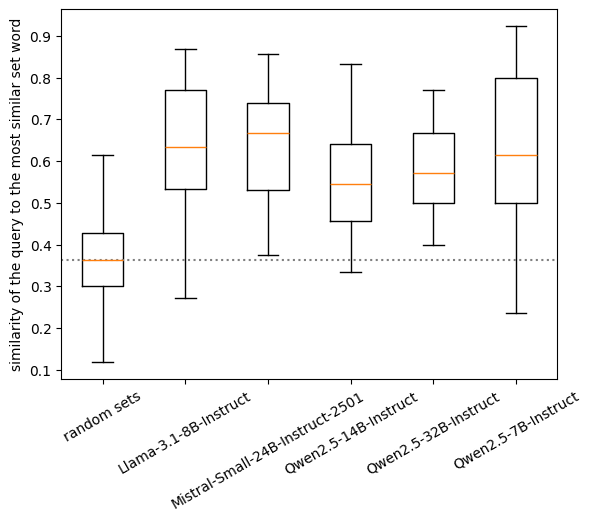

In [12]:
groups = fp.groupby('model')['similarity']
data = [reference['similarity']] + [g for _, g in groups]
labels = ['random sets'] + list(groups.groups)

plt.boxplot(data, showfliers=False)
plt.axhline(reference['similarity'].median(), color='gray', linestyle=':')

plt.xticks(range(1, len(labels)+1), labels, rotation=30)
plt.ylabel('similarity of the query to the most similar set word')
plt.show()

In [34]:
with pd.option_context('display.max_rows', None):
    display(fp.sort_values('similarity')[['model', 'query', 'set', 'similarity', 'substring']].head(15).round(3))
    display(fp.sort_values('similarity')[['model', 'query', 'set', 'similarity', 'substring']].tail(15).round(3))

,model,query,set,similarity,substring
235,Qwen2.5-7B-Instruct,anything,"(electrode, indictment, allegedly, salad)",0.235,False
211,Qwen2.5-7B-Instruct,incorrectly,"(neighborhood, shabby, dhabi, nephew)",0.261,False
319,Llama-3.1-8B-Instruct,individually,"(diagnostic, madden, identification, radar)",0.273,False
293,Llama-3.1-8B-Instruct,burglary,"(arbitrarily, arabic, myspace, silver)",0.316,False
70,Qwen2.5-14B-Instruct,enter,"(totalitarian, predominantly, verification, su...",0.333,False
200,Qwen2.5-7B-Instruct,dhabi,"(indispensable, helper, identification, receive)",0.333,False
51,Qwen2.5-14B-Instruct,crete,"(multiplication, subcommittee, intercourse, in...",0.353,False
72,Qwen2.5-14B-Instruct,strap,"(unparalleled, independently, architectural, d...",0.353,False
389,Mistral-Small-24B-Instruct-2501,garde,"(archaeology, cafeteria, overwhelmingly, child...",0.375,False
233,Qwen2.5-7B-Instruct,derogatory,"(filmmaker, transgender, scumbag, bakery)",0.375,False


,model,query,set,similarity,substring
298,Llama-3.1-8B-Instruct,produce,"(productive, pancake, neuroscience, providence)",0.824,False
284,Llama-3.1-8B-Instruct,effect,"(defect, conventional, marxist, vowel)",0.833,False
206,Qwen2.5-7B-Instruct,hanna,"(randy, authentication, rihanna, announcement)",0.833,True
201,Qwen2.5-7B-Instruct,later,"(platter, contamination, waiter, churchill)",0.833,False
216,Qwen2.5-7B-Instruct,trail,"(trainer, trailer, cafeteria, spiritually)",0.833,True
218,Qwen2.5-7B-Instruct,spice,"(lillian, hospice, accomplice, despicable)",0.833,True
286,Llama-3.1-8B-Instruct,forget,"(first, foremost, zelda, forgot)",0.833,False
65,Qwen2.5-14B-Instruct,bound,"(abundance, rebound, geographically, neighborh...",0.833,True
399,Mistral-Small-24B-Instruct-2501,rican,"(african, clandestine, mathematician, scare)",0.833,True
312,Llama-3.1-8B-Instruct,pathetic,"(empathy, sympathetic, handgun, liter)",0.842,True


## False negative errors: query words

In [15]:
fn = runs.query("task == 'fn' and method == 'greedy' and success").copy()
top = fn.groupby('model')['query'].value_counts().groupby('model').head(5).reset_index()
top['rank'] = top.groupby('model').cumcount() + 1
top['word'] = top['query'] + ' (' + top['count'].astype(str) + ')'
top.pivot(index='rank', columns='model', values='word').fillna('')

model,Llama-3.1-8B-Instruct,Mistral-Small-24B-Instruct-2501,Qwen2.5-14B-Instruct,Qwen2.5-32B-Instruct,Qwen2.5-7B-Instruct
rank,,,,,
1,invalid (8),comma (1),massachusetts (7),ordnance (10),belize (3)
2,incorrect (4),,hungary (5),portugal (10),denise (2)
3,dominic (3),,fatally (4),triumphant (3),negotiable (2)
4,professional (3),,authoritarian (3),bieber (2),partridge (2)
5,anonymous (1),,warsaw (3),brunswick (2),possibly (2)


## Transfer

In [16]:
rows = []
for path in RESULTS.glob('transfer/source=*/model=*.json'):
    source = path.parent.name.removeprefix('source=')
    for record in json.loads(path.read_text()):
        rows.append({
            'source': source,
            'source_model': record['model'].replace('--', '/').split('/')[-1],
            'target_model': record['target_model'].split('/')[-1],
            'task': 'fp' if '_fp_' in record['prompt'] else 'fn',
            'n_permutations': int(record['n-permutations']),
            'fooled': record['target_n_success'] / record['target_n_total'],
            'source_fooled': record['original_n_success'] / record['original_n_total'],
        })

transfer = pd.DataFrame(rows)

In [ ]:
# sanity check at reproducibility
same_model = transfer.query('source_model == target_model')
consistent = (same_model['fooled'] == same_model['source_fooled']).all()
print('consistent:', consistent)

consistent: True


In [18]:
# mean fraction of the 24 orderings fooled on the target model
for task in ['fp', 'fn']:
    t = transfer.query("source == 'greedy' and n_permutations == 1 and task == @task")
    matrix = t.pivot_table(
        index='source_model',
        columns='target_model',
        values='fooled'
    )
    display(
        matrix.style.background_gradient(vmin=0, vmax=0.4).format(precision=2)
    )

target_model,Llama-3.1-8B-Instruct,Mistral-Small-24B-Instruct-2501,Qwen2.5-14B-Instruct,Qwen2.5-32B-Instruct,Qwen2.5-7B-Instruct
source_model,,,,,
Llama-3.1-8B-Instruct,0.14,0.00,0.00,0.00,0.00
Mistral-Small-24B-Instruct-2501,0.05,0.36,0.00,0.06,0.00
Qwen2.5-14B-Instruct,0.02,0.17,0.14,0.18,0.00
Qwen2.5-32B-Instruct,0.02,0.10,0.00,0.32,0.00
Qwen2.5-7B-Instruct,0.03,0.09,0.01,0.01,0.12


target_model,Llama-3.1-8B-Instruct,Mistral-Small-24B-Instruct-2501,Qwen2.5-14B-Instruct,Qwen2.5-32B-Instruct,Qwen2.5-7B-Instruct
source_model,,,,,
Llama-3.1-8B-Instruct,0.24,0.00,0.00,0.00,0.03
Mistral-Small-24B-Instruct-2501,0.00,0.04,0.00,0.00,0.00
Qwen2.5-14B-Instruct,0.01,0.00,0.14,0.00,0.03
Qwen2.5-32B-Instruct,0.00,0.00,0.00,0.26,0.00
Qwen2.5-7B-Instruct,0.00,0.00,0.00,0.00,0.21


In [35]:
# share of found sets that fool the target model in at least one of the 24 orderings
for task in ['fp', 'fn']:
    t = transfer.query("source == 'greedy' and n_permutations == 1 and task == @task")
    matrix = t.assign(any_fooled=t['fooled'] > 0).pivot_table(
        index='source_model',
        columns='target_model',
        values='any_fooled'
    )
    display(matrix.style.background_gradient(vmin=0, vmax=1).format(precision=2))

target_model,Llama-3.1-8B-Instruct,Mistral-Small-24B-Instruct-2501,Qwen2.5-14B-Instruct,Qwen2.5-32B-Instruct,Qwen2.5-7B-Instruct
source_model,,,,,
Llama-3.1-8B-Instruct,1.00,0.00,0.00,0.00,0.00
Mistral-Small-24B-Instruct-2501,0.05,1.00,0.00,0.15,0.00
Qwen2.5-14B-Instruct,0.07,0.27,1.00,0.40,0.00
Qwen2.5-32B-Instruct,0.15,0.25,0.00,1.00,0.00
Qwen2.5-7B-Instruct,0.12,0.19,0.06,0.12,1.00


target_model,Llama-3.1-8B-Instruct,Mistral-Small-24B-Instruct-2501,Qwen2.5-14B-Instruct,Qwen2.5-32B-Instruct,Qwen2.5-7B-Instruct
source_model,,,,,
Llama-3.1-8B-Instruct,1.00,0.00,0.00,0.00,0.25
Mistral-Small-24B-Instruct-2501,0.00,1.00,0.00,0.00,0.00
Qwen2.5-14B-Instruct,0.05,0.00,1.00,0.00,0.15
Qwen2.5-32B-Instruct,0.00,0.00,0.00,1.00,0.00
Qwen2.5-7B-Instruct,0.00,0.00,0.00,0.00,1.00


## Word scan

In [ ]:
rows = []
for path in RESULTS.glob('word_scan/model=*/prompt=*/seed=*.json'):
    model = path.parts[-3].removeprefix('model=').split('--')[-1]
    task = 'fp' if '_fp_' in path.parts[-2] else 'fn'
    for record in json.loads(path.read_text()):
        rows.append({
            'model': model,
            'task': task,
            'word': record['word'],
            'position': record['position'],
            'error': record['success'],
            'wrong_prob': record['target_prob'],
            'set': tuple(record['words'][:-1]) if record['success'] else None, # only for errors
        })

scan = pd.DataFrame(rows)
fn_scan = scan.query("task == 'fn'").astype({'position': int})

In [20]:
# error rate on random word sets
rates = scan.groupby(['task', 'model'])['error'].agg(sets='size', errors='sum')
rates['rate_%'] = 100 * rates['errors'] / rates['sets']
rates.round(4)

sets  errors  rate_%
task model                                                  
fn   Llama-3.1-8B-Instruct            232280       2  0.0009
     Mistral-Small-24B-Instruct-2501  232280       1  0.0004
     Qwen2.5-14B-Instruct             232280       6  0.0026
     Qwen2.5-32B-Instruct             232280      22  0.0095
     Qwen2.5-7B-Instruct              232280     520  0.2239
fp   Llama-3.1-8B-Instruct            232280       2  0.0009
     Mistral-Small-24B-Instruct-2501  232280       1  0.0004
     Qwen2.5-14B-Instruct             232280       0  0.0000
     Qwen2.5-32B-Instruct             232280       0  0.0000
     Qwen2.5-7B-Instruct              232280       0  0.0000

In [ ]:
# which words cause errors
def words_for_half(words):
    counts = words.value_counts()
    return (counts.cumsum() < counts.sum() / 2).sum() + 1

def top_words(words, n=5):
    return ', '.join(f'{word} ({count})' for word, count in words.value_counts().head(n).items())

with pd.option_context('display.max_colwidth', 150):
    display(
        scan.query('error').groupby(['task', 'model'])['word'].agg(
            errors='size',
            words='nunique',
            words_for_half=words_for_half,
            top_words=top_words,
        )
    )

errors  words  words_for_half  \
task model                                                            
fn   Llama-3.1-8B-Instruct                 2      1               1   
     Mistral-Small-24B-Instruct-2501       1      1               1   
     Qwen2.5-14B-Instruct                  6      3               1   
     Qwen2.5-32B-Instruct                 22     13               3   
     Qwen2.5-7B-Instruct                 520    345              94   
fp   Llama-3.1-8B-Instruct                 2      2               1   
     Mistral-Small-24B-Instruct-2501       1      1               1   

                                                                                                         top_words  
task model                                                                                                          
fn   Llama-3.1-8B-Instruct                                                                             invalid (2)  
     Mistral-Small-24B-Instruct-2501                                                                   collage (1)  
     Qwen2.5-14B-Instruct                                        hungary (3), authoritarian (2), massachusetts (1)  
     Qwen2.5-32B-Instruct             ordnance (6), portugal (4), gardiner (2), complimentary (1), computation (1)  
     Qwen2.5-7B-Instruct                         knocks (6), wikipedia (6), lifeline (5), laurence (5), denise (5)  
fp   Llama-3.1-8B-Instruct                                                                    mater (1), steph (1)  
     Mistral-Small-24B-Instruct-2501                                                                     halle (1)

In [39]:
scan.query("task == 'fp' and error")[['model', 'word', 'set']]

,model,word,set
1754948,Llama-3.1-8B-Instruct,mater,"(materially, regulation, estrogen, darcy)"
1824886,Llama-3.1-8B-Instruct,steph,"(pronounce, stephanie, expansive, induce)"
2184891,Mistral-Small-24B-Instruct-2501,halle,"(selfishness, resemblance, hallelujah, clair)"


In [ ]:
# does the position of the matching word matter on random sets
# mean log probability of the wrong answer per position, e.g. -12 means ~1e-12
fn_scan.assign(log_wrong_prob=np.log10(fn_scan['wrong_prob'].clip(lower=1e-30))).pivot_table(
    index='model', columns='position', values='log_wrong_prob'
).round(2)

position,1,2,3,4
model,,,,
Llama-3.1-8B-Instruct,-5.08,-5.09,-5.18,-4.92
Mistral-Small-24B-Instruct-2501,-3.06,-3.15,-3.15,-3.03
Qwen2.5-14B-Instruct,-17.21,-17.38,-17.42,-17.40
Qwen2.5-32B-Instruct,-12.40,-11.93,-12.03,-11.90
Qwen2.5-7B-Instruct,-11.96,-12.24,-11.88,-11.12


In [ ]:
# do models find the same words vulnerable
# word vulnerability: mean prob of the wrong answer over its random sets
word_prob = fn_scan.groupby(['model', 'word'])['wrong_prob'].mean()
corr = word_prob.unstack('model').corr(method='spearman')
display(corr.style.background_gradient(vmin=0, vmax=1).format(precision=2))

model,Llama-3.1-8B-Instruct,Mistral-Small-24B-Instruct-2501,Qwen2.5-14B-Instruct,Qwen2.5-32B-Instruct,Qwen2.5-7B-Instruct
model,,,,,
Llama-3.1-8B-Instruct,1.00,0.36,0.06,-0.07,0.16
Mistral-Small-24B-Instruct-2501,0.36,1.00,-0.03,-0.07,0.16
Qwen2.5-14B-Instruct,0.06,-0.03,1.00,0.23,0.08
Qwen2.5-32B-Instruct,-0.07,-0.07,0.23,1.00,0.00
Qwen2.5-7B-Instruct,0.16,0.16,0.08,0.00,1.00
